# Modelo de 7 classes

## Bibliotecas utilizadas

In [2]:
import numpy as np
import os
import re
from matplotlib import pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, InputLayer, Masking
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.utils import to_categorical

## Definição das classes

In [3]:
actions = ['Alergia', 'Autismo', 'Bronquite', 'Caimbra', 'Convulsao', 'Diarreia', 'Fratura', 'Frieira', 'Infarto', 'Sarampo']
num_frames = 30

#Pares de sinais parecidos que viram uma classe só
merge_map = {
    'Alergia': 'Alergia_Frieira',
    'Frieira': 'Alergia_Frieira',
    'Caimbra': 'Caimbra_Fratura',
    'Fratura': 'Caimbra_Fratura',
    'Bronquite': 'Bronquite_Infarto',
    'Infarto': 'Bronquite_Infarto'
}

#Classes do problema de 7 classes e o número que representa cada uma
merged_actions = sorted(set(merge_map.get(a, a) for a in actions))
label_map = {label: num for num, label in enumerate(merged_actions)}

In [4]:
label_map

{'Alergia_Frieira': 0,
 'Autismo': 1,
 'Bronquite_Infarto': 2,
 'Caimbra_Fratura': 3,
 'Convulsao': 4,
 'Diarreia': 5,
 'Sarampo': 6}

## Carregamento dos dados

In [5]:
#Cada sujeito é um fold da validação cruzada (leave-one-subject-out)
subject_names = ['AL','e0','e1','e2','e3','ME','MV','RO','SA','MI']

#Dados de cada sujeito
#X_all: versões de cada vídeo com augmentation (usadas no treino)
#X_first: só a primeira versão de cada vídeo, sem augmentation (usada na validação)
subject_data = {
    s: {
        'X_all': [], 'y_all': [],
        'X_first': [], 'y_first': []
    }
    for s in subject_names
}

pad = len(str(num_frames - 1)) #Largura do zero à esquerda no nome dos arquivos (00.npy, 01.npy, ...)

#Nas classes que formam pares, só as 10 primeiras versões (_1 a _10) de cada vídeo entram no treino, para manter o balanceamento
versoes_descartadas = tuple(f'_{n}' for n in range(11, 21))

#Dados de treino: keypoints com augmentation
for action in actions:
    action_dir = os.path.join('../keypoints_data_augmented', action)
    for video_folder in os.listdir(action_dir):
        if action in merge_map and video_folder.endswith(versoes_descartadas):
            continue

        #Identifica o sujeito pelo nome da pasta (ex.: Alergia_AL_ALE_AL_01_1 -> AL)
        m = re.search(r'_(%s)_' % '|'.join(subject_names), video_folder)
        if not m:
            raise ValueError(f"Não achou sujeito em {video_folder}")
        subj = m.group(1)

        video_dir = os.path.join(action_dir, video_folder)
        window = []
        for frame_num in range(num_frames):
            fname = f"{frame_num:0{pad}d}.npy"
            fpath = os.path.join(video_dir, fname)
            if not os.path.exists(fpath):
                break
            res = np.load(fpath)
            window.append(res)

        if len(window) == num_frames:
            merged_label = merge_map.get(action, action)
            label = label_map[merged_label]
            subject_data[subj]['X_all'].append(window)
            subject_data[subj]['y_all'].append(label)

#Dados de validação: keypoints sem augmentation, só a primeira versão (_1) de cada vídeo
for action in actions:
    action_dir = os.path.join('../keypoints_data', action)
    for video_folder in os.listdir(action_dir):
        m = re.search(r'_(%s)_' % '|'.join(subject_names), video_folder)
        if not m:
            raise ValueError(f"Não achou sujeito em {video_folder}")
        subj = m.group(1)

        video_dir = os.path.join(action_dir, video_folder)
        window = []
        for frame_num in range(num_frames):
            fname = f"{frame_num:0{pad}d}.npy"
            fpath = os.path.join(video_dir, fname)
            if not os.path.exists(fpath):
                break
            res = np.load(fpath)
            window.append(res)

        if len(window) == num_frames and video_folder.endswith('_1'):
            merged_label = merge_map.get(action, action)
            label = label_map[merged_label]
            subject_data[subj]['X_first'].append(window)
            subject_data[subj]['y_first'].append(label)

#Converte para array e transforma os rótulos em one-hot
for s in subject_names:
    subject_data[s]['X_all'] = np.array(subject_data[s]['X_all'])
    subject_data[s]['y_all'] = to_categorical(subject_data[s]['y_all'], num_classes=len(merged_actions))
    subject_data[s]['X_first'] = np.array(subject_data[s]['X_first'])
    subject_data[s]['y_first'] = to_categorical(subject_data[s]['y_first'], num_classes=len(merged_actions))

## Parâmetros do modelo

In [6]:
neuronios = 32
dropout_recorrente = 0.2 #Taxa do dropout recorrente
batch_size = 128
taxa_aprendizado = 1e-3
weight_decay = 0.005 #Decaimento de peso do AdamW, fixo em todos os experimentos
epocas = 400


pasta_modelos = "models/7_classes"
os.makedirs(pasta_modelos, exist_ok=True)

## Validação cruzada (10-fold, leave-one-subject-out)

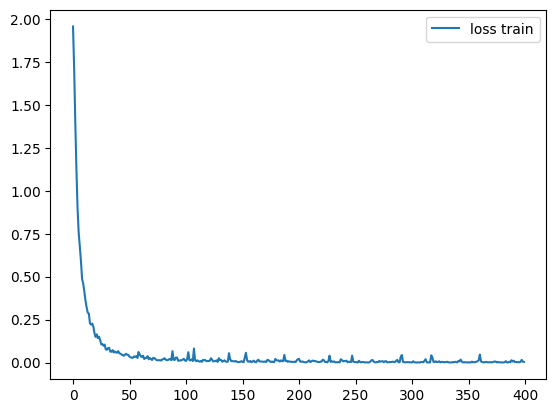

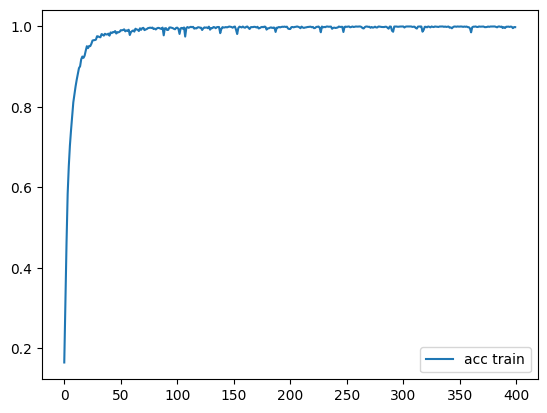

194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step

Fold 1 – Treino (AL excluído):
  Alergia_Frieira: 1.0000
  Autismo: 1.0000
  Bronquite_Infarto: 1.0000
  Caimbra_Fratura: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Sarampo: 1.0000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
Fold 1 – Validação (AL): acc = 0.9600
  Alergia_Frieira: 0.9000
  Autismo: 1.0000
  Bronquite_Infarto: 1.0000
  Caimbra_Fratura: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Sarampo: 0.8000


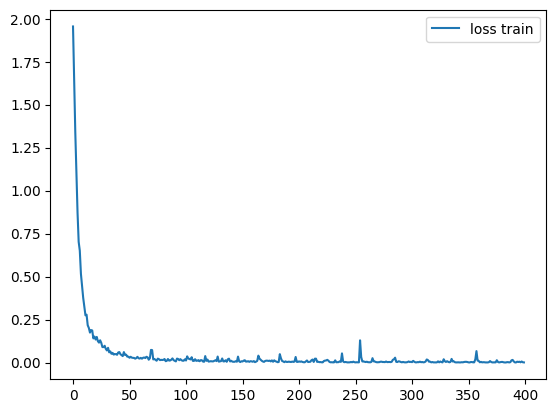

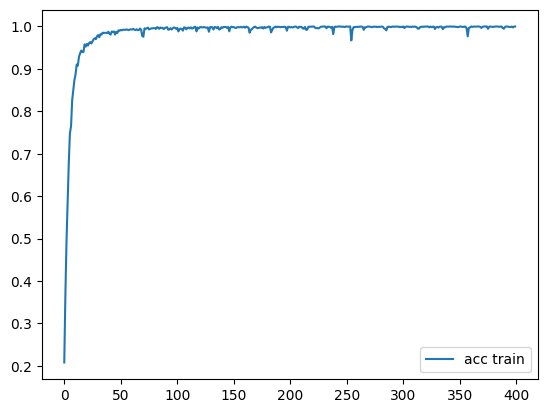

195/195 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step

Fold 2 – Treino (e0 excluído):
  Alergia_Frieira: 1.0000
  Autismo: 1.0000
  Bronquite_Infarto: 1.0000
  Caimbra_Fratura: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Sarampo: 1.0000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
Fold 2 – Validação (e0): acc = 0.8696
  Alergia_Frieira: 0.7000
  Autismo: 1.0000
  Bronquite_Infarto: 1.0000
  Caimbra_Fratura: 1.0000
  Convulsao: 0.4000
  Diarreia: 1.0000
  Sarampo: 1.0000


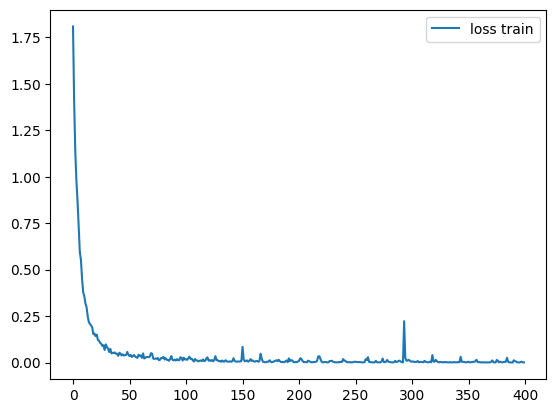

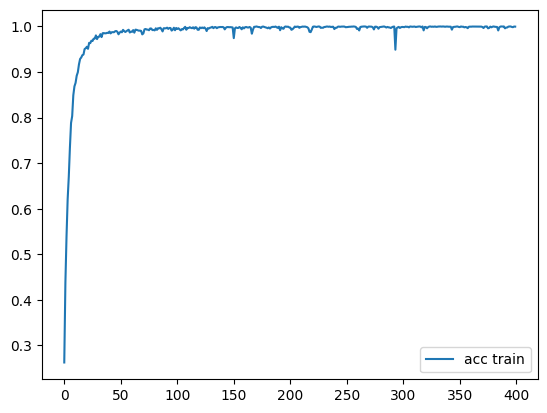

194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step

Fold 3 – Treino (e1 excluído):
  Alergia_Frieira: 1.0000
  Autismo: 1.0000
  Bronquite_Infarto: 1.0000
  Caimbra_Fratura: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Sarampo: 1.0000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
Fold 3 – Validação (e1): acc = 0.9000
  Alergia_Frieira: 1.0000
  Autismo: 1.0000
  Bronquite_Infarto: 1.0000
  Caimbra_Fratura: 1.0000
  Convulsao: 0.0000
  Diarreia: 1.0000
  Sarampo: 1.0000


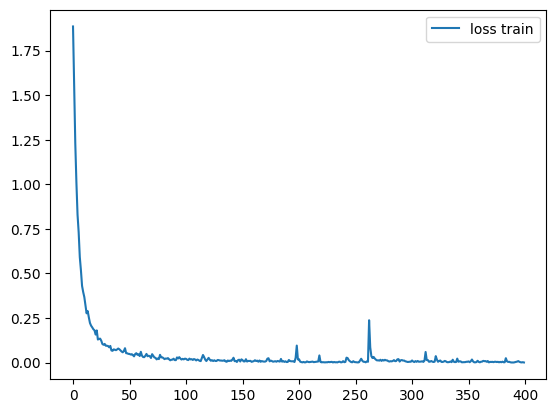

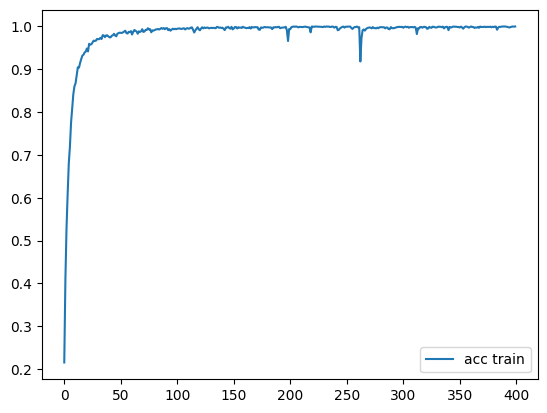

194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step

Fold 4 – Treino (e2 excluído):
  Alergia_Frieira: 1.0000
  Autismo: 1.0000
  Bronquite_Infarto: 1.0000
  Caimbra_Fratura: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Sarampo: 1.0000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
Fold 4 – Validação (e2): acc = 1.0000
  Alergia_Frieira: 1.0000
  Autismo: 1.0000
  Bronquite_Infarto: 1.0000
  Caimbra_Fratura: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Sarampo: 1.0000


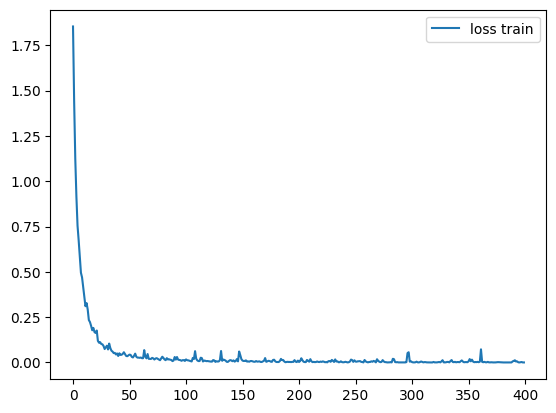

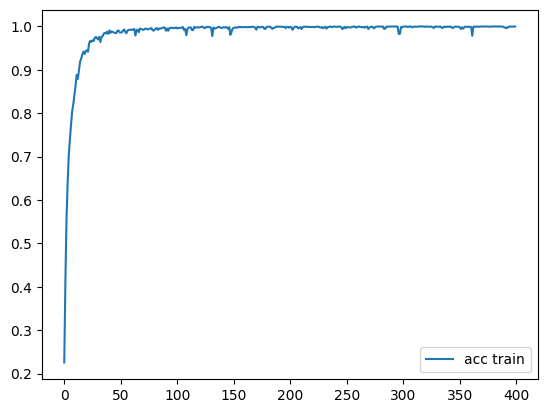

196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step

Fold 5 – Treino (e3 excluído):
  Alergia_Frieira: 1.0000
  Autismo: 1.0000
  Bronquite_Infarto: 1.0000
  Caimbra_Fratura: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Sarampo: 1.0000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
Fold 5 – Validação (e3): acc = 0.8913
  Alergia_Frieira: 1.0000
  Autismo: 1.0000
  Bronquite_Infarto: 1.0000
  Caimbra_Fratura: 1.0000
  Convulsao: 1.0000
  Diarreia: 0.4000
  Sarampo: 0.0000


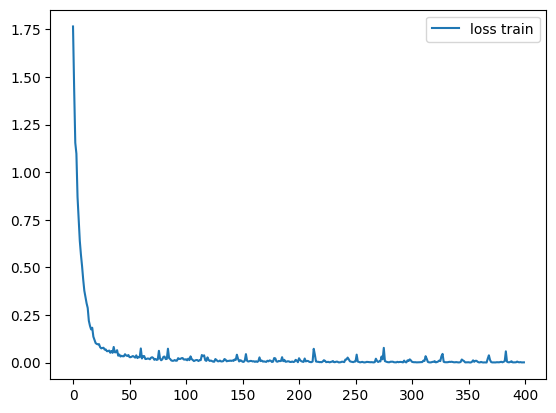

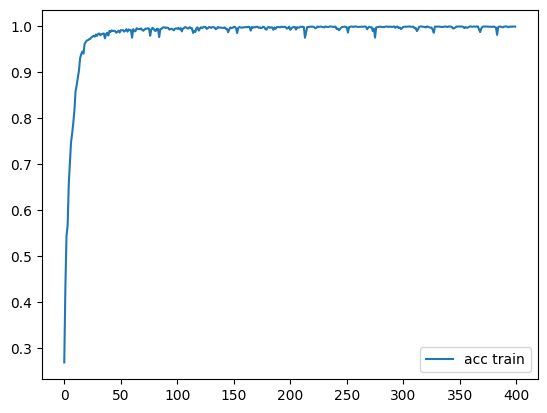

194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step

Fold 6 – Treino (ME excluído):
  Alergia_Frieira: 1.0000
  Autismo: 1.0000
  Bronquite_Infarto: 1.0000
  Caimbra_Fratura: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Sarampo: 1.0000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
Fold 6 – Validação (ME): acc = 0.9200
  Alergia_Frieira: 0.8000
  Autismo: 1.0000
  Bronquite_Infarto: 1.0000
  Caimbra_Fratura: 0.8000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Sarampo: 1.0000


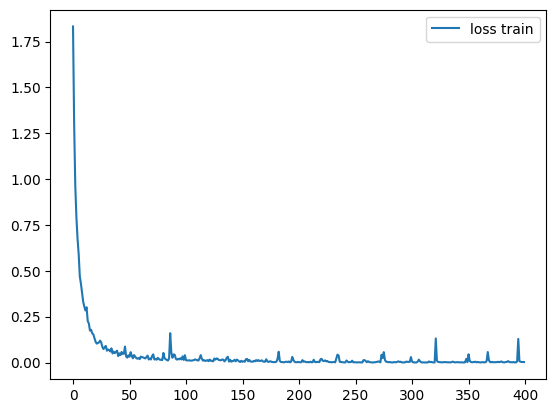

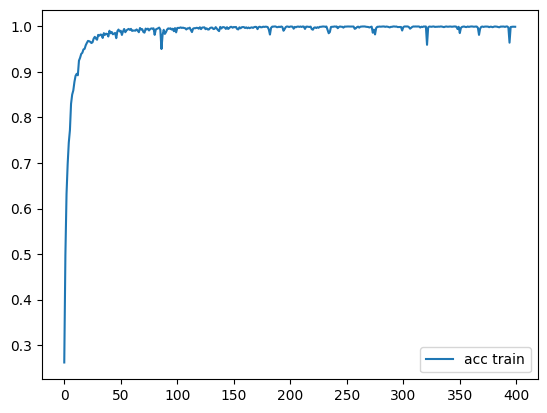

194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step

Fold 7 – Treino (MV excluído):
  Alergia_Frieira: 1.0000
  Autismo: 1.0000
  Bronquite_Infarto: 1.0000
  Caimbra_Fratura: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Sarampo: 1.0000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
Fold 7 – Validação (MV): acc = 0.9800
  Alergia_Frieira: 1.0000
  Autismo: 1.0000
  Bronquite_Infarto: 1.0000
  Caimbra_Fratura: 0.9000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Sarampo: 1.0000


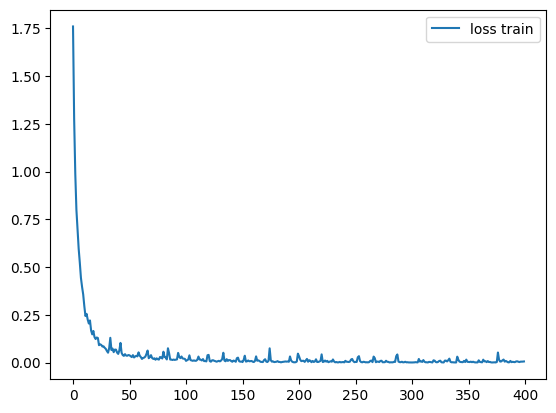

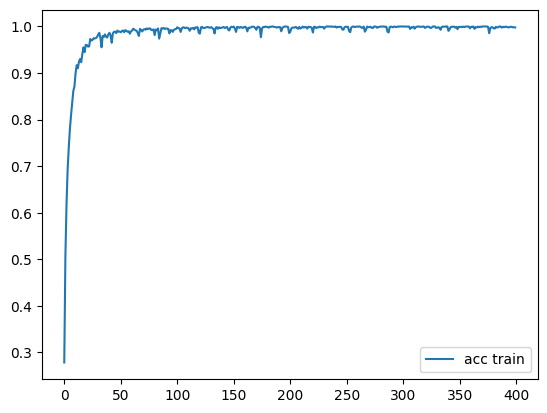

194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step

Fold 8 – Treino (RO excluído):
  Alergia_Frieira: 1.0000
  Autismo: 1.0000
  Bronquite_Infarto: 1.0000
  Caimbra_Fratura: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Sarampo: 1.0000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
Fold 8 – Validação (RO): acc = 1.0000
  Alergia_Frieira: 1.0000
  Autismo: 1.0000
  Bronquite_Infarto: 1.0000
  Caimbra_Fratura: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Sarampo: 1.0000


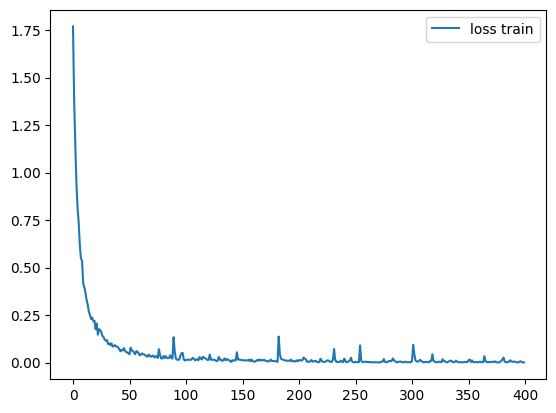

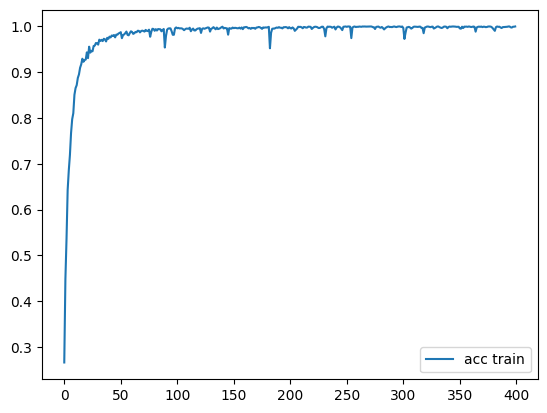

194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step

Fold 9 – Treino (SA excluído):
  Alergia_Frieira: 1.0000
  Autismo: 1.0000
  Bronquite_Infarto: 1.0000
  Caimbra_Fratura: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Sarampo: 1.0000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
Fold 9 – Validação (SA): acc = 0.9800
  Alergia_Frieira: 1.0000
  Autismo: 1.0000
  Bronquite_Infarto: 1.0000
  Caimbra_Fratura: 1.0000
  Convulsao: 1.0000
  Diarreia: 0.8000
  Sarampo: 1.0000


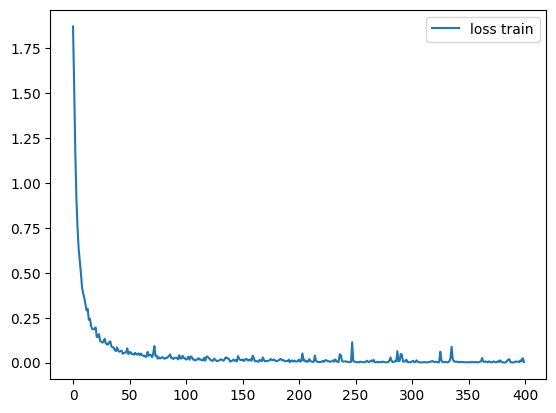

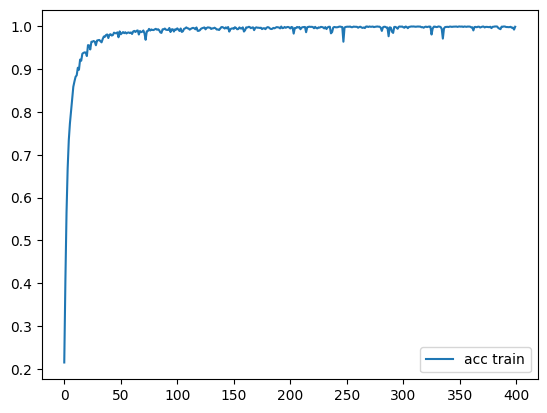

194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step

Fold 10 – Treino (MI excluído):
  Alergia_Frieira: 1.0000
  Autismo: 1.0000
  Bronquite_Infarto: 1.0000
  Caimbra_Fratura: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Sarampo: 1.0000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
Fold 10 – Validação (MI): acc = 0.9600
  Alergia_Frieira: 0.9000
  Autismo: 1.0000
  Bronquite_Infarto: 0.9000
  Caimbra_Fratura: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Sarampo: 1.0000

Acurácia Total = 0.9461  |  Desvio = 0.0449
Acurácia Geral = 0.9472


In [8]:
#Listas para juntar as predições de todos os folds
yhat_all = []
ytrue_all = []
fold_results = []

def class_acc(true, pred, labels):
    #Retorna a acurácia de cada classe
    acc = {}
    for i,lbl in enumerate(labels):
        idx = np.where(true == i)[0]
        acc[lbl] = np.mean(pred[idx]==true[idx]) if len(idx)>0 else 0
    return acc

labels = list(label_map.keys())

#Cada fold deixa um sujeito de fora para a validação
for i, val_subj in enumerate(subject_names):
    #Validação: sujeito excluído. Treino: todos os demais
    X_val, y_val = subject_data[val_subj]['X_first'], subject_data[val_subj]['y_first']

    X_train = np.concatenate([subject_data[s]['X_all'] for s in subject_names if s != val_subj])
    y_train = np.concatenate([subject_data[s]['y_all'] for s in subject_names if s != val_subj])

    model = Sequential()
    model.add(InputLayer(input_shape=(num_frames, 225)))
    model.add(Masking(mask_value=0.0))
    model.add(LSTM(neuronios,
        activation='relu',
        return_sequences=False,
        recurrent_dropout=dropout_recorrente))
    model.add(Dense(7, activation='softmax'))
    model.compile(optimizer=AdamW(taxa_aprendizado, weight_decay=weight_decay),
                  loss='categorical_crossentropy',
                  metrics=['categorical_accuracy'])

    hist = model.fit(X_train, y_train,
                     batch_size=batch_size, epochs=epocas, verbose=0)
    model.save(f"{pasta_modelos}/model_fold_{i+1}.keras")

    plt.plot(hist.history['loss'], label='loss train')
    plt.legend()
    plt.show()
    plt.plot(hist.history['categorical_accuracy'], label='acc train')
    plt.legend()
    plt.show()

    #Acurácia por classe no treino
    y_pred_tr = np.argmax(model.predict(X_train), axis=1)
    y_true_tr = np.argmax(y_train, axis=1)
    print(f"\nFold {i+1} – Treino ({val_subj} excluído):")
    for lbl, a in class_acc(y_true_tr, y_pred_tr, labels).items():
        print(f"  {lbl}: {a:.4f}")

    #Acurácia por classe na validação
    y_pred_v = np.argmax(model.predict(X_val), axis=1)
    y_true_v = np.argmax(y_val, axis=1)
    yhat_all.append(y_pred_v)
    ytrue_all.append(y_true_v)

    acc_v = np.mean(y_pred_v == y_true_v)
    fold_results.append(acc_v)
    print(f"Fold {i+1} – Validação ({val_subj}): acc = {acc_v:.4f}")
    for lbl, a in class_acc(y_true_v, y_pred_v, labels).items():
        print(f"  {lbl}: {a:.4f}")

#Média e desvio padrão da acurácia entre os folds
media = np.mean(fold_results)
std = np.std(fold_results)
print(f"\nAcurácia Total = {media:.4f}  |  Desvio = {std:.4f}")

#Acurácia geral, juntando as predições de todos os folds
y_true_final = np.concatenate(ytrue_all)
y_pred_final = np.concatenate(yhat_all)
acc_final = np.mean(y_pred_final == y_true_final)
print(f"Acurácia Geral = {acc_final:.4f}")

## Modelo final (treinado com todos os dados)

Shape X_all: (6880, 30, 225)
Shape y_all: (6880, 7)
Epoch 1/400
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - categorical_accuracy: 0.1778 - loss: 1.9373
Epoch 2/400
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - categorical_accuracy: 0.2686 - loss: 1.8250
Epoch 3/400
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - categorical_accuracy: 0.3276 - loss: 1.6587
Epoch 4/400
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - categorical_accuracy: 0.3811 - loss: 1.5173
Epoch 5/400
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - categorical_accuracy: 0.4677 - loss: 1.2936
Epoch 6/400
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - categorical_accuracy: 0.5583 - loss: 1.0927
Epoch 7/400
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - categorical_accuracy: 0.6759 - loss: 0.8647
Epoch 8/400
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - categorical_accuracy: 0.7400 - loss: 0.7150
Epoch 9/400
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - categorical_accuracy: 0.8019 - loss: 0.5698
Epoch 10/400
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - categorical

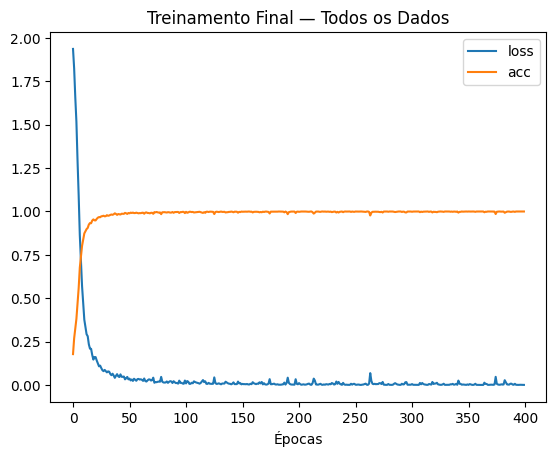

215/215 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step

Acurácia total (auto-avaliação): 1.0000


In [9]:
#Junta os dados de treino de todos os sujeitos
X_all = np.concatenate([subject_data[s]['X_all'] for s in subject_names])
y_all = np.concatenate([subject_data[s]['y_all'] for s in subject_names])

print(f"Shape X_all: {X_all.shape}")
print(f"Shape y_all: {y_all.shape}")

model = Sequential()
model.add(InputLayer(input_shape=(num_frames, 225)))
model.add(Masking(mask_value=0.0))
model.add(LSTM(neuronios,
               activation='relu',
               return_sequences=False,
               recurrent_dropout=dropout_recorrente))
model.add(Dense(7, activation='softmax'))
model.compile(optimizer=AdamW(taxa_aprendizado, weight_decay=weight_decay),
              loss='categorical_crossentropy',
              metrics=['categorical_accuracy'])
hist = model.fit(X_all, y_all,
                 batch_size=batch_size,
                 epochs=epocas,
                 verbose=1)

model.save(f"{pasta_modelos}/model_final_all.keras")

#Curvas de perda e acurácia do treino
plt.plot(hist.history['loss'], label='loss')
plt.plot(hist.history['categorical_accuracy'], label='acc')
plt.legend()
plt.title("Treinamento Final — Todos os Dados")
plt.xlabel("Épocas")
plt.show()

#Acurácia do modelo final nos próprios dados de treino
y_pred = np.argmax(model.predict(X_all), axis=1)
y_true = np.argmax(y_all, axis=1)

acc_final = np.mean(y_pred == y_true)
print(f"\nAcurácia total (auto-avaliação): {acc_final:.4f}")